
# Lab w12: An LLM in a Skinner Box
## CSE5026 Foundation and Frontiers of Cognitive Science

**Research question:** If one lever delivers a food pellet every time it is pressed and the other never does, can an LLM use feedback to find the active lever and keep choosing it?

Read **Operant Chamber** on page 2 of the [CheeseBench paper](https://arxiv.org/pdf/2604.10825). The chamber has a left lever (`L`), a right lever (`R`), and a food magazine. One lever stays active throughout each session. There is no cue light to identify it. 

Under the condition of continuous reinforcement, each press of the active lever delivers one pellet. `pellet=1` means a pellet was delivered on that press; `pellet=0` means none was delivered.

First, press the levers yourself. Then run two comparison policies and let an LLM play in the same chamber. 
The manual exercise and both comparison policies work without an API.

Before running the notebook, follow the [English setup guide](README_en.md) to install CheeseBench and select the `cogsci` kernel.

In [1]:
import matplotlib.pyplot as plt
from operant_lab import Chamber, configured_llm, feedback_policy, random_policy, run_session, save_csv

## 1. Press the levers manually

Run the setup cell for the chamber once. Then edit and rerun the **press cell** to choose one lever at a time. Try to identify the active lever in four presses. In the drawing, `[=]` is a lever, `[_]` marks a recently pressed lever, and `[m]` / `[M]` are the two states of the food magazine display. Use `pellet` to tell whether the current press delivered food.

In [2]:
box = Chamber(seed=11, presses=4)
print(box.observation)

###########################
#     [=]         [=]     #
#           [m]           #
#.........................#
#.........................#
#.........................#
#.........................#
#............↑............#
###########################


In [3]:
choice = "L"  # Change to "R", or press "L" again
print(f"Press {box.press_count + 1}: {choice}, pellet={box.press(choice)}")
print(box.observation)

Press 1: L, pellet=0
###########################
#     [_]         [=]     #
#           [m]           #
#.........................#
#.........................#
#.........................#
#.........................#
#............↑............#
###########################


## 2. Run two comparison policies

Predict which cumulative pellet curve will be steeper. 

The **random policy** is equally likely to choose either lever on each press, independently of previous choices. It gets six pellets per 12 presses on average. 

The **feedback policy** starts on the left, repeats its last choice after a pellet, and switches sides if no pellet was delivered. This is a rule we programmed as a simple baseline.

Each policy runs in two sessions, with a different active lever in each. All policies face the same active lever within a given session.

In [ ]:
SEEDS = (10, 11)
PRESSES = 12

baseline_runs = {
    seed: {
        "Random": run_session(random_policy(seed + 100), label="Random", seed=seed, presses=PRESSES),
        "Win-stay / lose-shift": run_session(feedback_policy(), label="Win-stay / lose-shift",
                                            seed=seed, presses=PRESSES),
    }
    for seed in SEEDS
}

## 3. Let the LLM choose

Follow the [setup guide](README_en.md) to configure the model endpoint, then set `RUN_LLM = True`. 

The model receives the current view of the chamber and the choices and pellet feedback from **this session**. It must return one `L` or `R` per call. 

The prompt does not identify the active lever, and the model starts each session with an empty history. Its weights remain unchanged throughout the exercise. (the model is not fine-tuned, of course)

The default is two sessions, for 24 LLM calls. To start with just one session, set `LLM_SEEDS = SEEDS[:1]`. Record which model you used.

In [17]:
import os
from getpass import getpass

os.environ["LAB_API_KEY"] = getpass("Paste your DeepSeek API key: ").strip()
os.environ["LAB_BASE_URL"] = "https://api.deepseek.com"
os.environ["LAB_MODEL"] = "deepseek-flash"

RUN_LLM = True

In [21]:
LLM_SEEDS = SEEDS
llm_runs = {}

if RUN_LLM:
    pick = configured_llm()
    model_name = os.environ["LAB_MODEL"]
    print(f"Model: {model_name}")

    for seed in LLM_SEEDS:
        llm_runs[seed] = run_session(pick, label=model_name, seed=seed, presses=PRESSES)
        actions = " ".join(row["choice"] for row in llm_runs[seed])
        print(f"Session {seed} choices: {actions}")
else:
    print("Offline run: Random and Win-stay / lose-shift only.")

Model: deepseek-flash
Session 1 choices: L L L L L L L L L L L L
Session 2 choices: L L L L L L L L L L L L


## 4. Read the plot and check the trial data

Each upward step in a cumulative curve marks a press of the active lever. A flat segment means no pellet was delivered. 
The horizontal axis counts lever choices.

Compare the total number of pellets, **the press that earned the first pellet**, and **the number of correct choices in the final six presses**. 

The number of effective lever presses equals the number of pellets.

If the orange reference and the green model follow the same path, their curves share the same coordinates. The dashed green line is drawn over a wider solid orange line so both remain visible.

Session 1, active lever: L
  Random                 first pellet:    1 | last 6 correct: 2/6 | total: 6
  Win-stay / lose-shift  first pellet:    1 | last 6 correct: 6/6 | total: 12
  deepseek-flash         first pellet:    1 | last 6 correct: 6/6 | total: 12
  deepseek-flash and Win-stay / lose-shift overlap at every press.
Session 2, active lever: L
  Random                 first pellet:    1 | last 6 correct: 3/6 | total: 6
  Win-stay / lose-shift  first pellet:    1 | last 6 correct: 6/6 | total: 12
  deepseek-flash         first pellet:    1 | last 6 correct: 6/6 | total: 12
  deepseek-flash and Win-stay / lose-shift overlap at every press.


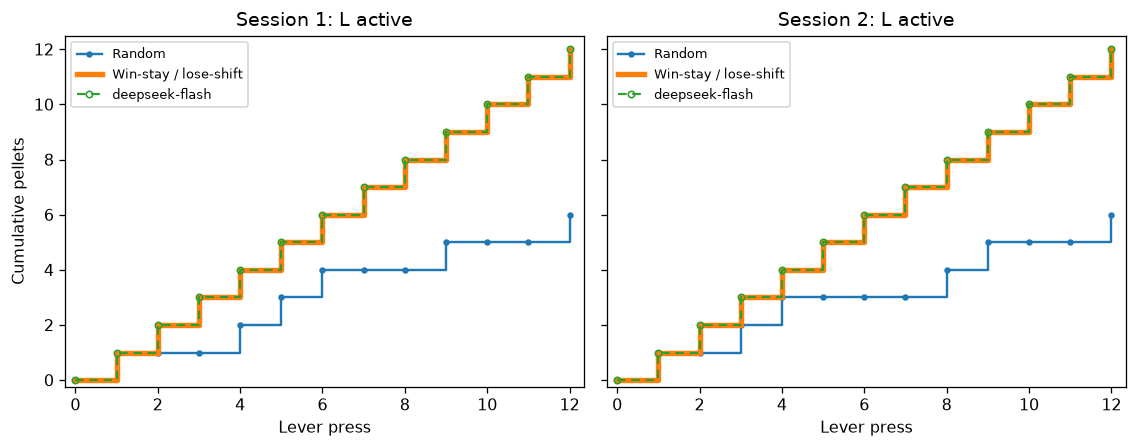

In [22]:
fig, axes = plt.subplots(1, len(SEEDS), figsize=(10, 4), sharey=True, squeeze=False)
rows = []

for ax, seed in zip(axes[0], SEEDS):
    runs = baseline_runs[seed].copy()
    if seed in llm_runs:
        runs[llm_runs[seed][0]["agent"]] = llm_runs[seed]
    active = runs["Random"][0]["active_side"]
    print(f"Session {seed}, active lever: {active}")
    # Keep a wider solid baseline visible beneath a dashed model curve.
    styles = {
        "Random": dict(color="tab:blue", linestyle="-", marker=".", zorder=2),
        "Win-stay / lose-shift": dict(color="tab:orange", linestyle="-", linewidth=3.4, zorder=3),
    }
    model_style = dict(color="tab:green", linestyle=(0, (4, 2.6)), linewidth=1.35,
                       marker="o", markersize=4, markerfacecolor="none", zorder=4)
    for name, log in runs.items():
        rows.extend(log)
        ax.step([0] + [r["press"] for r in log], [0] + [r["total"] for r in log],
                where="post", label=name, **styles.get(name, model_style))
        first = next((r["press"] for r in log if r["pellet"]), None)
        late = log[-6:]
        late_correct = sum(r["choice"] == active for r in late)
        print(f"  {name:22} first pellet: {str(first):>4} | "
              f"last {len(late)} correct: {late_correct}/{len(late)} | total: {log[-1]['total']}")
    if seed in llm_runs:
        model_log = llm_runs[seed]
        reference = runs["Win-stay / lose-shift"]
        if [(r["press"], r["total"]) for r in model_log] == [(r["press"], r["total"]) for r in reference]:
            print(f"  {model_log[0]['agent']} and Win-stay / lose-shift overlap at every press.")
    ax.set(title=f"Session {seed}: {active} active", xlabel="Lever press",
           xlim=(-0.25, PRESSES + 0.35), ylim=(-0.25, PRESSES + 0.5))
    ax.legend(loc="upper left", fontsize=8)

axes[0, 0].set_ylabel("Cumulative pellets")
fig.tight_layout()
plt.show()

save_csv("operant_results.csv", rows)

## 5. Get the results from two different models

- See if you can catch a difference in model behaviors.
- Change the `schedule` argument of `create_operant_chamber()` in `operant_lab.py` to other modes, and watch if the curves are different. 
- For instance, the default mode "FR1" means "fixed ratio", and food comes in every 1 press. You can change to "FR3" to enable every 3 presses. You can even try "VR3" for variable ratio.